# Atelier AI - Candidates, Features and Reference Methods

Find plausible historical articles before ranking them. Fix one future-independent cohort, construct at most one row per customer/article/cutoff, and compare three simple recommendation methods against complete next-week relevance.

The [reference plan](../docs/implementation_plan.md) maps these notebook sections to candidate generation and baseline evaluation. All dates come from the shared temporal configuration.

## 1. Fixed parameters and source tables

The cohort contains 20,000 customer IDs selected by seeded SHA-256 ordering of the complete customer table. Selection does not depend on future purchases. This benchmark population does not establish historical account existence.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown
import atelier_ai
from atelier_ai.temporal_protocol import load_protocol
from atelier_ai.notebook_tools import show_figure

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
protocol = load_protocol(PROJECT_ROOT)

from atelier_ai.preparation import prepare_sources
from atelier_ai.workflow import cohort, build_context, target_reference, reference_dict, evaluate_methods, export_validation
from atelier_ai.recommendation_features import retrieve_candidates, prepare_feature_tables, build_checked_feature_batch, feature_contract
prepare_sources(PROJECT_ROOT)
customer_ids=cohort(PROJECT_ROOT)
cutoff=protocol['validation_start']
display(pd.Series({'cohort_customers':len(customer_ids),'seed':42,'history_days':180,'validation_cutoff':str(cutoff.date()),'candidate_budget':300,'recommendations_per_customer':12}))

cohort_customers                     20000
seed                                    42
history_days                           180
validation_cutoff               2020-09-02
candidate_budget                       300
recommendations_per_customer            12
dtype: object

## 2. Historical retrieval context

Personal history uses [cutoff - 180 days, cutoff). Global popularity uses all source customers, with 7-day and 28-day counts inside that historical interval. Metadata classifications are used under a documented stability assumption. Future purchases do not enter retrieval.

In [2]:
context=build_context(PROJECT_ROOT,customer_ids,cutoff)
assert context['history']['t_dat'].lt(cutoff).all()
display(context['popularity'].sort_values(['article_recent_rows','article_id'],ascending=[False,True]).head(12))

,article_id,article_recent_rows,article_rows_28d,article_recency_days,product_group_name,product_type_name,colour_group_name
1361,0898694001,950,1020,1.0,Garment Upper body,Blazer,Light Beige
25701,0933706001,920,920,1.0,Garment Upper body,Blouse,Blue
35930,0751471001,846,2052,1.0,Garment Lower body,Trousers,Black
49838,0915526001,797,1387,1.0,Garment Upper body,Sweater,Off White
43503,0915529003,750,1146,1.0,Garment Upper body,Sweater,Black
39039,0706016001,701,1868,1.0,Garment Lower body,Trousers,Black
20136,0918292001,662,1784,1.0,Garment Lower body,Leggings/Tights,Black
46654,0751471043,653,1378,1.0,Garment Lower body,Trousers,Black
34903,0915526002,622,1364,1.0,Garment Upper body,Sweater,Black
39599,0915529001,565,1121,1.0,Garment Upper body,Sweater,Beige


## 3. Candidate sources and deterministic priority

1. The latest 30 distinct personal articles, ties by article ID.
2. Global top 100 articles by 7-day purchase-row count.
3. Top 50 recent articles in each of the customer's three preferred product types.
4. Fill to 300 distinct articles using 28-day global popularity.

Preferred types use 180-day personal row counts, ties by type name. Within a type, popularity uses 7-day rows, ties by article ID. Source overlap is deduplicated. Previously purchased articles remain eligible. A customer without history uses global popularity. No future target article is injected into the pool.

,history_proposed,global_proposed,category_proposed,fallback_added,candidate_rows
count,20000.000000,20000.0,20000.000000,20000.000000,20000.0
mean,4.500250,100.0,64.336500,138.469700,300.0
std,7.163677,0.0,66.982251,65.395425,0.0
min,0.000000,100.0,0.000000,21.000000,300.0
25%,0.000000,100.0,0.000000,65.000000,300.0
50%,1.000000,100.0,50.000000,156.000000,300.0
75%,6.000000,100.0,150.000000,200.000000,300.0
max,30.000000,100.0,150.000000,200.000000,300.0


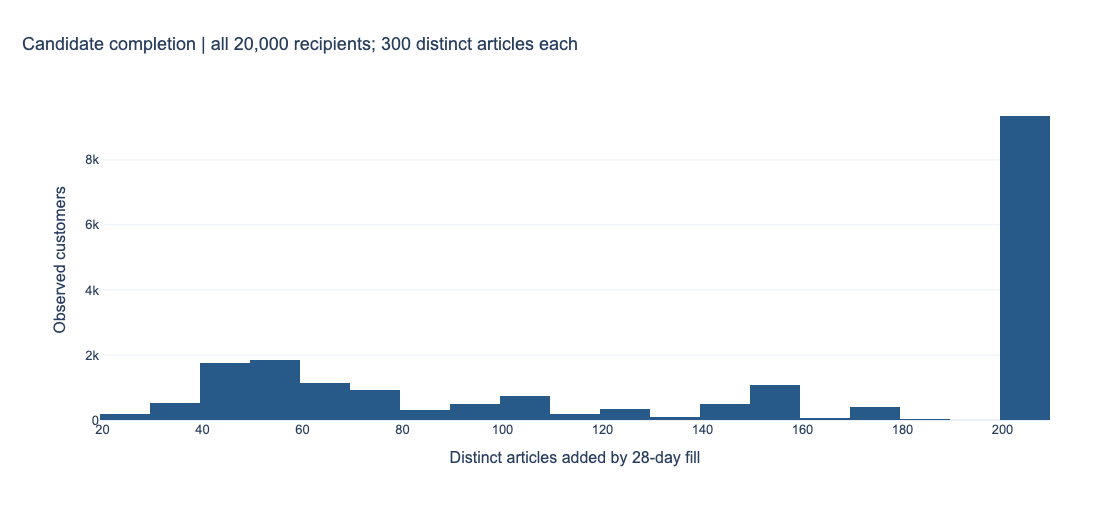

In [3]:
pools,memberships,baseline_rows,candidate_audit=retrieve_candidates(customer_ids,context)
assert all(len(values)==len(set(values))==300 for values in pools.values())
assert candidate_audit['history_proposed'].le(30).all()
assert candidate_audit['global_proposed'].le(100).all()
assert candidate_audit['category_proposed'].le(150).all()
display(candidate_audit.describe())
fig=px.histogram(candidate_audit,x='fallback_added',nbins=30,
    labels={'fallback_added':'Distinct articles added by 28-day fill','count':'Cohort customers'},
    title='Candidate completion | all 20,000 recipients; 300 distinct articles each')
show_figure(fig,PROJECT_ROOT,'candidates_fallback')

**Interpretation.** Proposal counts overlap and cannot be added to obtain distinct candidate counts. The fill count measures articles actually added after deduplication. Retrieval coverage, measured next, is an upper bound on what the ranker can recover from this pool.

## 4. Complete validation reference and three baselines

Relevance is a distinct customer-article pair purchased during the next seven days. Source repetitions remain in a separate transaction table. All cohort customers receive twelve recommendations; customers without target purchases are excluded only from target-based averages, with their share reported.

Compare global 7-day popularity, preferred-type popularity, and recent personal purchases. All use a popularity fallback, identical recipients and complete reference targets. A missed target stays in the metric denominator.

source_target_rows                    3803
distinct_customer_article_targets     3428
target_buyers                         1065
recommendation_recipients            20000
dtype: int64

,method,recommendation_customers,evaluated_customers,excluded_customers,excluded_share_pct,target_pairs,retrieved_target_pairs,map_at_k,recall_at_k,ndcg_at_k,micro_recall_at_k,candidate_coverage,catalogue_coverage,mean_recommended_product_groups
0,recent_popularity_7d,20000,1065,18935,94.675,3428,68,0.006091,0.022700,0.012546,0.019837,0.196616,0.000240,3.00000
1,preferred_product_types,20000,1065,18935,94.675,3428,52,0.005346,0.014352,0.009923,0.015169,0.196616,0.017120,1.93685
2,recent_purchases_180d,20000,1065,18935,94.675,3428,123,0.025445,0.055198,0.036811,0.035881,0.196616,0.334306,3.22520


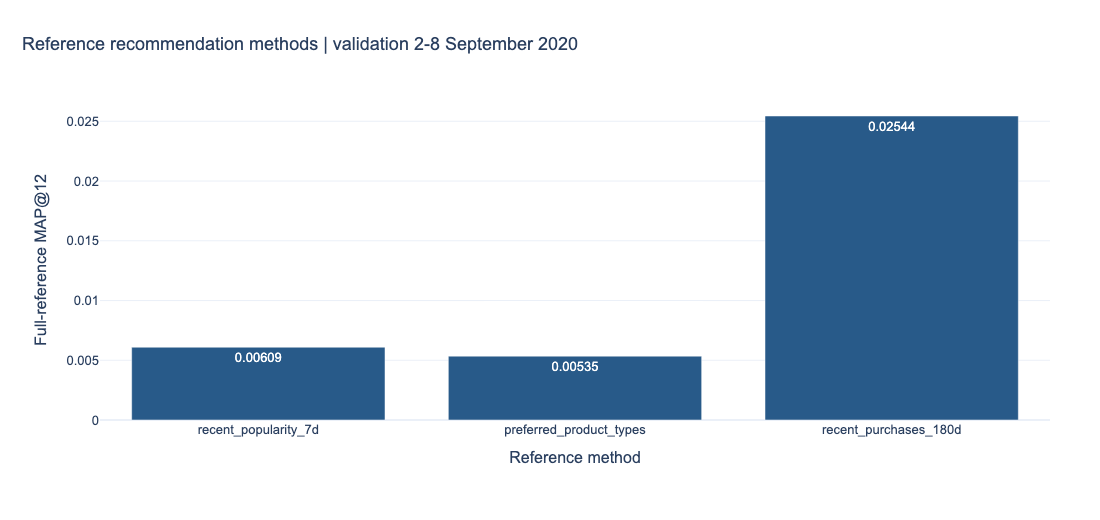

In [4]:
target_rows,targets=target_reference(PROJECT_ROOT,customer_ids,cutoff)
methods={name:{c:values[name] for c,values in baseline_rows.items()} for name in next(iter(baseline_rows.values()))}
baseline_comparison,baseline_evaluations=evaluate_methods(PROJECT_ROOT,customer_ids,targets,methods,context,pools)
display(pd.Series({'source_target_rows':len(target_rows),'distinct_customer_article_targets':len(targets),'target_buyers':targets['customer_id'].nunique(),'recommendation_recipients':len(customer_ids)}))
display(baseline_comparison)
fig=px.bar(baseline_comparison,x='method',y='map_at_k',text_auto='.5f',
    labels={'method':'Reference method','map_at_k':'Full-reference MAP@12'},
    title='Reference recommendation methods | validation 2-8 September 2020')
show_figure(fig,PROJECT_ROOT,'baseline_comparison')

**Interpretation.** MAP@12 is the equal-weight mean over customers with at least one target purchase. Candidate coverage uses all distinct target pairs, including those absent from retrieval. Source rows, target pairs and evaluated customers are different denominators. These are validation comparisons, not independent test results.

## 5. Feature contract and temporal semantics

Each feature row represents one customer, one candidate article and one cutoff. Features cover customer activity, article popularity and trend, customer-article history, category/colour affinities, prediction context and retrieval memberships.

Count and share features use zero for absent observed history. Unobserved recencies and source ranks remain missing; LightGBM can handle these missing values. Raw IDs and classification names are audit fields, not ordered numeric model inputs. No learned imputation or encoding is fitted at this milestone.

In [5]:
display(feature_contract)
feature_tables=prepare_feature_tables(customer_ids,context,memberships)
pilot_ids=customer_ids[:100]
pilot_pairs=pd.DataFrame([(c,a,cutoff) for c in pilot_ids for a in pools[c]],columns=['customer_id','article_id','cutoff'])
pilot_features=build_checked_feature_batch(pilot_pairs,feature_tables)
assert len(pilot_features)==30_000
display(pilot_features.head())
display(pilot_features.isna().sum().loc[lambda s:s.gt(0)].to_frame('missing_pilot_rows'))

,feature,family,missing_policy,meaning
0,customer_history_rows,customer,0,Purchase rows in the preceding 180 days
1,customer_distinct_articles,customer,0,Distinct articles in the preceding 180 days
2,customer_recency_days,customer,NaN,Days since the last observed purchase
3,customer_has_history,customer,False,Any purchase in the preceding 180 days
4,customer_rows_7d,customer,0,Purchase rows in the preceding 7 days
5,customer_rows_28d,customer,0,Purchase rows in the preceding 28 days
6,customer_rows_90d,customer,0,Purchase rows in the preceding 90 days
7,customer_distinct_product_types,customer,0,Distinct product types in 180-day history
8,customer_distinct_colours,customer,0,Distinct colour groups in 180-day history
9,article_recent_rows,article,0,Global purchase rows in the preceding 7 days


,customer_id,article_id,cutoff,product_group_name,dominant_product_group,customer_history_rows,customer_distinct_articles,customer_recency_days,customer_has_history,customer_rows_7d,...,prediction_weekday,prediction_iso_week,customer_channel_2_share,from_history,from_category,from_global,from_fallback_28d,history_source_rank,category_source_rank,n_retrieval_sources
0,cbcb6cf21b3e0ada7e40afefec120a2d7bc92a2faf716a...,0898694001,2020-09-02,Garment Upper body,NaN,0,0,NaN,False,0,...,2,36,0.0,False,False,True,False,NaN,NaN,1
1,cbcb6cf21b3e0ada7e40afefec120a2d7bc92a2faf716a...,0933706001,2020-09-02,Garment Upper body,NaN,0,0,NaN,False,0,...,2,36,0.0,False,False,True,False,NaN,NaN,1
2,cbcb6cf21b3e0ada7e40afefec120a2d7bc92a2faf716a...,0751471001,2020-09-02,Garment Lower body,NaN,0,0,NaN,False,0,...,2,36,0.0,False,False,True,False,NaN,NaN,1
3,cbcb6cf21b3e0ada7e40afefec120a2d7bc92a2faf716a...,0915526001,2020-09-02,Garment Upper body,NaN,0,0,NaN,False,0,...,2,36,0.0,False,False,True,False,NaN,NaN,1
4,cbcb6cf21b3e0ada7e40afefec120a2d7bc92a2faf716a...,0915529003,2020-09-02,Garment Upper body,NaN,0,0,NaN,False,0,...,2,36,0.0,False,False,True,False,NaN,NaN,1


,missing_pilot_rows
dominant_product_group,13500
customer_recency_days,13500
article_recent_rank,53
customer_article_recency_days,29659
history_source_rank,29659
category_source_rank,24079


## 6. Pilot source overlaps

The 100 pilot customers are the first IDs in fixed cohort order, not selected by their target activity. Source membership counts overlap. This pilot checks feature definitions; it does not estimate population quality.

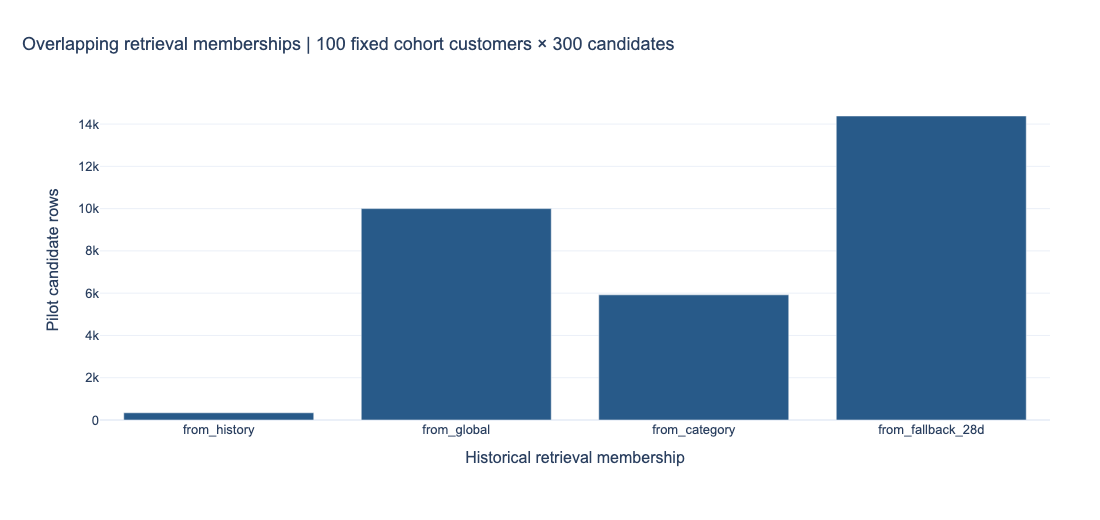

In [6]:
source_counts=pilot_features[['from_history','from_global','from_category','from_fallback_28d']].sum().rename_axis('source').reset_index(name='candidate_rows')
fig=px.bar(source_counts,x='source',y='candidate_rows',
    labels={'source':'Historical retrieval membership','candidate_rows':'Pilot candidate rows'},
    title='Overlapping retrieval memberships | 100 fixed cohort customers × 300 candidates')
show_figure(fig,PROJECT_ROOT,'feature_pilot_sources')

## 7. Verified full-cohort export

Build features in customer-complete batches of 500. Every partition has explicit storage types, exact Parquet round-trip checks and a checksum. The manifest records the source, cohort, configuration and Python-module hashes. Matching complete exports are verified and reused; different identities create different directories.

In [7]:
validation_index,verified_baselines=export_validation(PROJECT_ROOT)
assert validation_index['candidate_rows']==6_000_000
display(pd.Series(validation_index))
display(verified_baselines)

Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified feature partitions: 15; customers: 7,500
Verified feature partitions: 20; customers: 10,000
Verified feature partitions: 25; customers: 12,500
Verified feature partitions: 30; customers: 15,000
Verified feature partitions: 35; customers: 17,500
Verified feature partitions: 40; customers: 20,000


directory                  data/processed/weekly_v1/features/validation_2...
fingerprint                2910e6b0936f01998ecfdbb0fa30cea1409de544f55fa5...
cohort_sha256              5dcab30d63b42ad6f677fcec8cefade3964300890bba58...
cutoff                                                            2020-09-02
source_transaction_rows                                                 3803
target_pairs                                                            3428
buyers                                                                  1065
feature_count                                                             31
candidate_rows                                                       6000000
dtype: object

,method,recommendation_customers,evaluated_customers,excluded_customers,excluded_share_pct,target_pairs,retrieved_target_pairs,map_at_k,recall_at_k,ndcg_at_k,micro_recall_at_k,candidate_coverage,catalogue_coverage,mean_recommended_product_groups
0,recent_popularity_7d,20000,1065,18935,94.675,3428,68,0.006091,0.022700,0.012546,0.019837,0.196616,0.000240,3.00000
1,preferred_product_types,20000,1065,18935,94.675,3428,52,0.005346,0.014352,0.009923,0.015169,0.196616,0.017120,1.93685
2,recent_purchases_180d,20000,1065,18935,94.675,3428,123,0.025445,0.055198,0.036811,0.035881,0.196616,0.334306,3.22520


## Next step

Recompute the same retrieval and features at each of six historical cutoffs. Attach labels only after candidates are fixed, preserve complete reference targets, and audit training-group eligibility separately from evaluation eligibility.